# Dataset Type

In [ ]:
DATASET_TYPE = "internal" # Options are "internal" or "downloaded"

# Load Data

In [ ]:
# Import scikit-learn dataset library
from sklearn import datasets

if DATASET_TYPE == "internal":
  dt_data = datasets.load_breast_cancer()

  X = dt_data.data
  y = dt_data.target

  feature_names = dt_data.feature_names
  labels = dt_data.target_names
  cm_labels = labels

# OR: Download Dataset from file

In [ ]:
import numpy as np
import pandas as pd

if DATASET_TYPE == "downloaded":
  dt_data = pd.read_csv('http://nrvis.com/data/mldata/breast-cancer-wisconsin_wdbc.csv')

  X = dt_data.iloc[:, 2:].to_numpy()
  y = dt_data.iloc[:, 1].to_numpy()
  feature_names = dt_data.columns[2:]
  labels = feature_names[1]
  cm_labels = ["malignant", "benign"]

  # Map labels from ['M', 'B'] to [0, 1] space
  y = np.where(y=='M', 0, 1)

# Explore the Data

In [ ]:
# print the names of the features
print("Features: ", feature_names)

# print the label type of targets
print("Labels: ", labels)

Features:  Index(['radius (nucA)', 'texture (nucA)', 'perimeter (nucA)', 'area (nucA)',
       'smoothness (nucA)', 'compactness (nucA)', 'concavity (nucA)',
       'concave points (nucA)', 'symmetry (nucA)', 'fractal dimension (nucA)',
       'radius (nucB)', 'texture (nucB)', 'perimeter (nucB)', 'area (nucB)',
       'smoothness (nucB)', 'compactness (nucB)', 'concavity (nucB)',
       'concave points (nucB)', 'symmetry (nucB)', 'fractal dimension (nucB)',
       'radius (nucC)', 'texture (nucC)', 'perimeter (nucC)', 'area (nucC)',
       'smoothness (nucC)', 'compactness (nucC)', 'concavity (nucC)',
       'concave points (nucC)', 'symmetry (nucC)', 'fractal dimension (nucC)'],
      dtype='object')
Labels:  texture (nucA)


# Split the Data into Train and Test Sets

In [ ]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((455, 30), (114, 30), (455,), (114,))

# Generate the Model

In [ ]:
from sklearn.tree import DecisionTreeClassifier # Import Decision Tree Classifier

# Update hyperparameters like criterion, max_depth, min_samples_split etc. using details available at -
# https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

# Create Decision Tree classifer object
clf = DecisionTreeClassifier()

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

# Predict on Test Data

In [ ]:
#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Evaluate on Test data

In [ ]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy: how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Model Precision: what percentage of positive tuples are labeled as such?
print("Precision:",metrics.precision_score(y_test, y_pred))

# Model Recall: what percentage of positive tuples are labelled as such?
print("Recall:",metrics.recall_score(y_test, y_pred))

Accuracy: 0.9298245614035088
Precision: 0.9459459459459459
Recall: 0.9459459459459459


# Plot Confusion Matrix

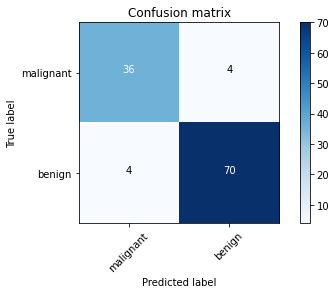

In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion matrix', cmap=plt.cm.Blues):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt), horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

cm = confusion_matrix(y_test, y_pred)

plot_confusion_matrix(cm, cm_labels)  
plt.show()

# Visualize the Tree

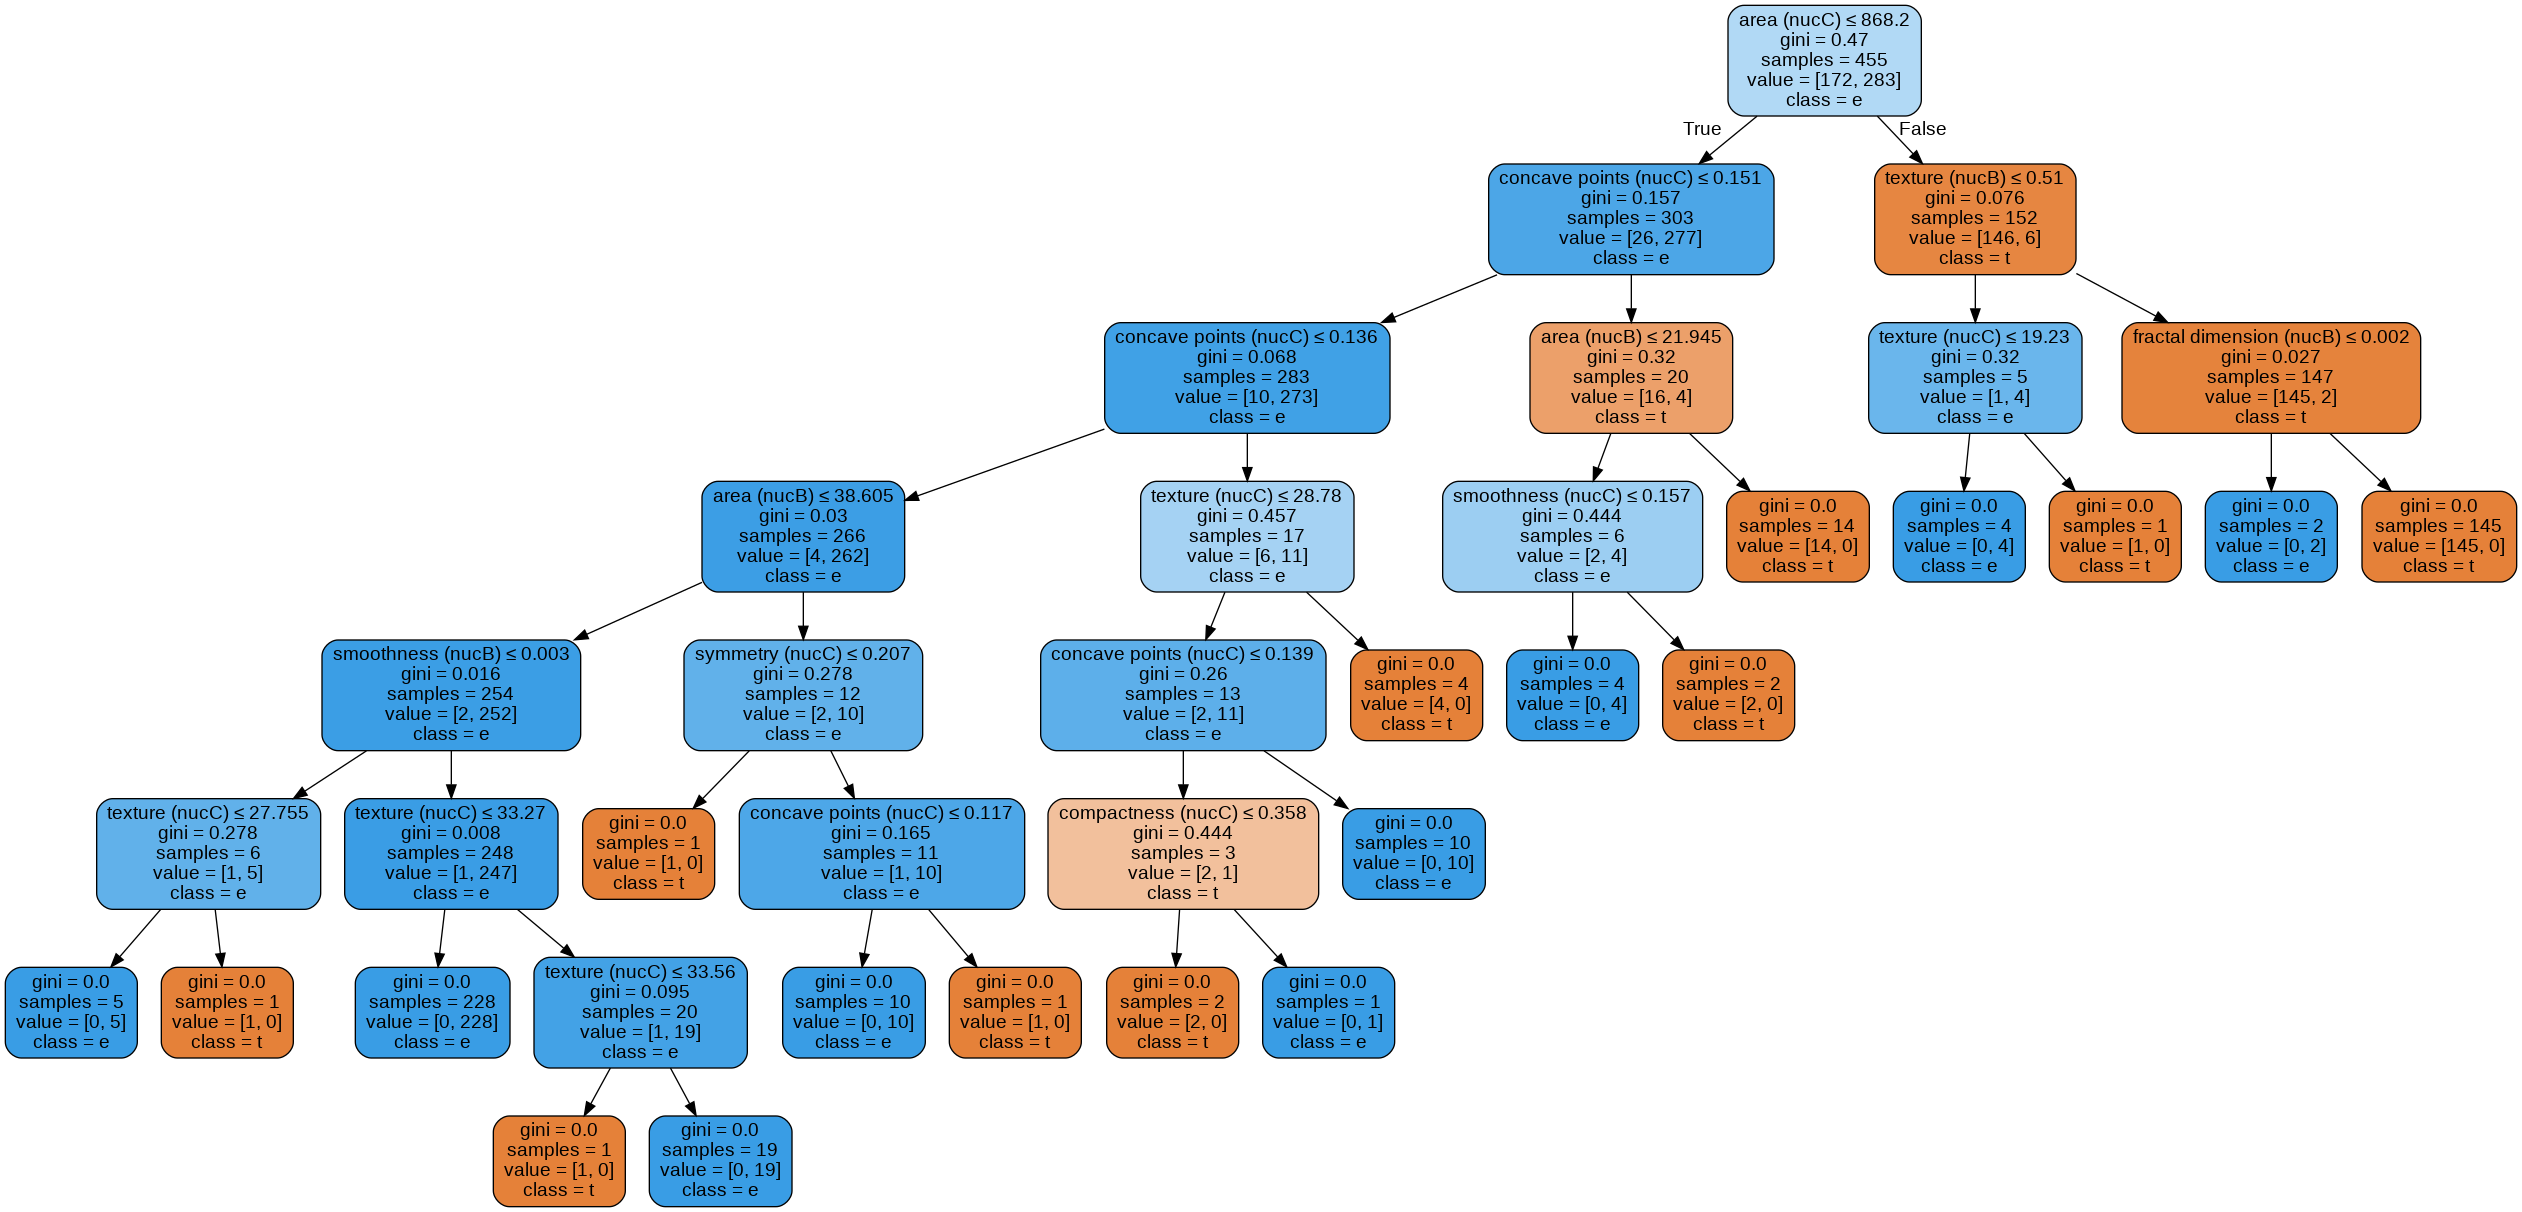

In [ ]:
from sklearn.tree import export_graphviz
from sklearn.externals.six import StringIO  
from IPython.display import Image  
import pydotplus

dot_data = StringIO()
export_graphviz(clf, out_file=dot_data,  
                filled=True, rounded=True,
                special_characters=True,feature_names=feature_names,class_names=labels)
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('decision_tress.png')
Image(graph.create_png())